# Onboarding 03 - PCA, ridge, and evaluation

This notebook turns image embeddings into expression predictions. PCA (principal component analysis) compresses correlated input features into a smaller set of directions. Ridge regression is a linear model that limits coefficient size to reduce overfitting. The PCA fitting/reconstruction ideas from the earlier PCA notebooks are incorporated here.

The notebook compares random spot, slide, and patient folds. Fitting choices - including gene selection, scaling, PCA, and ridge regularization - use training data only. Patient-level evaluation is the main generalization result. Set `N_FOLDS = 4` for the full 23-patient cohort; use 3 folds for the three-patient smoke run. [Study notes](../../docs/study_materials.md).


## Install this notebook's analysis dependencies

In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge

**Storage:** Use the same data root as Notebooks 01?02. Mount Drive in Colab if needed; local and Drive Desktop paths work through the shared setting.

In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local runtime: no Drive mount needed.')

Local runtime: no Drive mount needed.


**If you are using shared folder locally in Google Drive:** If the base folder is in a shared folder, you need to first create a shortcut in your own drive for it to be seen on Google Drive Desktop. This shortcut will be stored as a link (`.lnk` file). We can retrieve the location it points to with the `pylnk3` package. 
```python
%pip install -q pylnk3
```

```python
import pylnk3
BASE_DIR_NAME = pylnk3.Lnk('G:/location/to/your/shortcut').path
```

## Settings

- `SPLITS`: which splits to run. All three give the leakage table
- `N_FOLDS`: number of outer folds. It can't be more than the number of patients: **3** for the 3-patient test run, **4** for all 23 patients
- `N_INNER_FOLDS`: folds inside the training set for choosing λ (fewer if there aren't enough patients or sections)
- `N_GENES`: genes to predict, chosen by variance on training spots in each fold
- `N_PCS`: PCA components (256, as in HEST)
- `ALPHAS`: the λ values ridge tries, 0.01 to 100,000
- `MIN_TEST_SD`: genes whose test SD is below this are skipped for NRMSE (dividing by ~0 would blow up)

In [4]:
from pathlib import Path
BASE_DIR_NAME = '../'  # Edit this base folder to match Notebooks 01 and 02.
SPLITS = ['spot', 'slide', 'patient']
N_FOLDS = 3  # The checked-in cohort has three patients; increase for larger cohorts.
N_INNER_FOLDS = 3
N_GENES, N_PCS = 50, 256
ALPHAS = np.logspace(-2, 5, 30)
MIN_TEST_SD = 0.05
SEED = 0


In [5]:
BASE_DIR = Path(BASE_DIR_NAME).expanduser().resolve()
DATA_DIR = BASE_DIR / 'data'
EXPRESSION_DIR = DATA_DIR / 'expression'
EMBEDDING_DIR = DATA_DIR / 'embeddings'
RESULTS_DIR = BASE_DIR / 'outputs'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Reading:', DATA_DIR, '\nSaving results:', RESULTS_DIR)


Reading: C:\Users\Siyu_\Documents\JHU_Files\courses\697_BDD\Hist2ST\data 
Saving results: C:\Users\Siyu_\Documents\JHU_Files\courses\697_BDD\Hist2ST\outputs


## Step 1. Load embeddings and expression

For each section we load its embeddings (Notebook 2) and its log1p expression (Notebook 1), then stack all sections. Both files have their rows in the same spot order, and we check the barcodes to be sure.

- `X`: embeddings, one row per spot, 4,608 columns (model input)
- `Y`: log1p expression, one row per spot, one column per shared gene (target). Kept sparse to save memory
- `spots`: the spot table rows in the same order (section, patient, barcode)

In [6]:
spot_table = pd.read_csv(DATA_DIR / "spot_table.csv")
with (DATA_DIR / "genes.txt").open() as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(EMBEDDING_DIR / f"{sample_id}.npz", allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(EXPRESSION_DIR / f"{sample_id}.npz")
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"])
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)

print("X (embeddings):", X.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (3663, 4608)
Y (log1p expression): (3663, 13875)
Sections: 9  Patients: 3


## Step 2. Make the folds for each split

Each spot gets a fold number. In fold *k*, the spots with fold *k* are the test set and everything else is training.

- **spot:** spots are shuffled and dealt into folds at random
- **slide:** all spots of a section get the same fold (`GroupKFold` grouped by `sample_id`)
- **patient:** all spots of a patient get the same fold (`GroupKFold` grouped by `patient`)

The check at the end makes sure no section (slide split) or patient (patient split) is ever in both train and test.

In [7]:
def group_column(split):
    if split == "slide":
        return "sample_id"
    if split == "patient":
        return "patient"
    return None


def make_folds(split, n_folds):
    fold_of_spot = np.zeros(len(spots), dtype=int)
    column = group_column(split)

    if column is None:
        splitter = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
        fold_splits = splitter.split(X)
    else:
        n_groups = spots[column].nunique()
        if n_folds > n_groups:
            raise ValueError(f"N_FOLDS = {n_folds} but there are only {n_groups} groups for the {split} split.")
        splitter = GroupKFold(n_splits=n_folds)
        fold_splits = splitter.split(X, groups=spots[column])

    for fold, (train_index, test_index) in enumerate(fold_splits):
        fold_of_spot[test_index] = fold
    return fold_of_spot


fold_assignments = spots[["sample_id", "patient", "barcode"]].copy()
for split in SPLITS:
    fold_assignments[split] = make_folds(split, N_FOLDS)

for split in SPLITS:
    column = group_column(split)
    print(f"--- {split} split ---")
    for fold in range(N_FOLDS):
        is_test = fold_assignments[split] == fold
        test_patients = sorted(spots.loc[is_test, "patient"].unique())
        test_sections = sorted(spots.loc[is_test, "sample_id"].unique())
        print(f"fold {fold}: {is_test.sum()} test spots | test patients: {test_patients} | test sections: {len(test_sections)}")
        if column is not None:
            train_groups = set(spots.loc[~is_test, column])
            test_groups = set(spots.loc[is_test, column])
            assert len(train_groups & test_groups) == 0, f"{split} fold {fold}: a {column} is in both train and test"

fold_assignments.to_csv(RESULTS_DIR / "fold_assignments.csv", index=False)

--- spot split ---
fold 0: 1221 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 9
fold 1: 1221 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 9
fold 2: 1221 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 9
--- slide split ---
fold 0: 1222 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 3
fold 1: 1240 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 3
fold 2: 1201 test spots | test patients: ['BC23209', 'BC23268', 'BC23269'] | test sections: 3
--- patient split ---
fold 0: 1422 test spots | test patients: ['BC23268'] | test sections: 3
fold 1: 1299 test spots | test patients: ['BC23269'] | test sections: 3
fold 2: 942 test spots | test patients: ['BC23209'] | test sections: 3


## Step 3. The pieces of one fold

**Choose genes (training spots only).** Variance of each gene's log1p expression across training spots; keep the top `N_GENES`. Using all spots here would let the test spots influence which genes we predict, a small leak.

**Choose λ per gene (inner split).** Inside the training set we split again, grouped the same way as the outer split: by patient for the patient split, by section for the slide split, random for the spot split. For each λ we train on the inner-train part and measure the error on the inner-validation part, and each gene keeps the λ with the lowest average error. The test spots are never used to choose λ.

The inner split works on the PCA scores from the outer training set. PCA sees no gene values, so this is a common simplification; the test set stays completely untouched.

**Score.** For each gene on the test spots:
- **PCC:** does the prediction go up where the gene really goes up? (undefined if either side is constant)
- **RMSE:** average size of the error, in log1p units
- **NRMSE** = RMSE ÷ the gene's test SD: 1 ≈ no better than predicting the average

In [8]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def choose_alpha_per_gene(P_train, y_train, inner_groups):
    if inner_groups is None:
        n_inner = N_INNER_FOLDS
        inner_splits = KFold(n_splits=n_inner, shuffle=True, random_state=SEED).split(P_train)
    else:
        n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
        inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        prediction = model.predict(P_test).reshape(len(P_test), -1)
        y_pred[:, genes_with_this_alpha] = prediction
    return y_pred


def pcc_one_gene(true_values, predicted_values):
    if np.std(true_values) < 1e-6 or np.std(predicted_values) < 1e-6:
        return np.nan
    return np.corrcoef(true_values, predicted_values)[0, 1]


def score_genes(y_true, y_pred):
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2, axis=0))
    sd = np.std(y_true, axis=0)
    nrmse = np.where(sd >= MIN_TEST_SD, rmse / np.maximum(sd, 1e-12), np.nan)
    pcc = np.array([pcc_one_gene(y_true[:, g], y_pred[:, g]) for g in range(y_true.shape[1])])
    return rmse, nrmse, pcc

**One fold, start to finish.** Every step that learns from data (genes, scaler, PCA, λ, ridge) is fit on `train_index` only, then applied to `test_index`.

In [9]:
def run_one_fold(split, fold):
    is_test = fold_assignments[split].to_numpy() == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler()
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    n_components = min(N_PCS, Z_train.shape[0], Z_train.shape[1])
    pca = PCA(n_components=n_components, random_state=SEED)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    column = group_column(split)
    inner_groups = None if column is None else spots[column].to_numpy()[train_index]
    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, inner_groups)

    y_pred_ridge = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_pred_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    rmse, nrmse, pcc = score_genes(y_test, y_pred_ridge)
    rmse_mean, nrmse_mean, _ = score_genes(y_test, y_pred_mean)

    gene_rows = pd.DataFrame({
        "split": split,
        "fold": fold,
        "gene": all_genes[gene_index],
        "PCC": pcc,
        "RMSE": rmse,
        "NRMSE": nrmse,
        "alpha": alpha_per_gene,
    })

    fold_row = {
        "split": split,
        "fold": fold,
        "n_train": len(train_index),
        "n_test": len(test_index),
        "n_pcs": n_components,
        "test_patients": " ".join(sorted(spots["patient"].iloc[test_index].unique())),
        "test_sections": " ".join(sorted(spots["sample_id"].iloc[test_index].unique())),
        "ridge_PCC": np.nanmean(pcc),
        "ridge_PCC_median": np.nanmedian(pcc),
        "ridge_RMSE": np.mean(rmse),
        "ridge_NRMSE": np.nanmean(nrmse),
        "mean_predictor_RMSE": np.mean(rmse_mean),
        "mean_predictor_NRMSE": np.nanmean(nrmse_mean),
        "median_alpha": np.median(alpha_per_gene),
    }
    return fold_row, gene_rows

## Step 4. Run every split and fold

In [10]:
fold_rows = []
gene_tables = []

for split in SPLITS:
    for fold in range(N_FOLDS):
        fold_row, gene_rows = run_one_fold(split, fold)
        fold_rows.append(fold_row)
        gene_tables.append(gene_rows)
        print(f"{split:8s} fold {fold}: train {fold_row['n_train']:6d}  test {fold_row['n_test']:6d}  "
              f"PCC {fold_row['ridge_PCC']:.3f}  NRMSE {fold_row['ridge_NRMSE']:.3f}", flush=True)

fold_scores = pd.DataFrame(fold_rows)
gene_scores = pd.concat(gene_tables, ignore_index=True)

spot     fold 0: train   2442  test   1221  PCC 0.705  NRMSE 0.698
spot     fold 1: train   2442  test   1221  PCC 0.700  NRMSE 0.704
spot     fold 2: train   2442  test   1221  PCC 0.694  NRMSE 0.709
slide    fold 0: train   2441  test   1222  PCC 0.574  NRMSE 0.918
slide    fold 1: train   2423  test   1240  PCC 0.667  NRMSE 0.750
slide    fold 2: train   2462  test   1201  PCC 0.617  NRMSE 0.805
patient  fold 0: train   2241  test   1422  PCC 0.139  NRMSE 1.245
patient  fold 1: train   2364  test   1299  PCC 0.156  NRMSE 1.420
patient  fold 2: train   2721  test    942  PCC 0.137  NRMSE 3.843


## Step 5. The leakage table

The same model, scored three ways. Each number is the average over folds (± SD across folds).

What to expect: **spot > slide > patient**. The drop from spot to patient is how much of the spot-split score came from spatial leakage. The patient-split number is the honest one.

In [11]:
leakage_rows = []
for split in SPLITS:
    rows = fold_scores[fold_scores["split"] == split]
    leakage_rows.append({
        "split": split,
        "folds": len(rows),
        "PCC_mean": rows["ridge_PCC"].mean(),
        "PCC_sd": rows["ridge_PCC"].std(),
        "NRMSE_mean": rows["ridge_NRMSE"].mean(),
        "NRMSE_sd": rows["ridge_NRMSE"].std(),
        "RMSE_mean": rows["ridge_RMSE"].mean(),
        "mean_predictor_NRMSE": rows["mean_predictor_NRMSE"].mean(),
    })

leakage_table = pd.DataFrame(leakage_rows)
print(leakage_table.round(3).to_string(index=False))

  split  folds  PCC_mean  PCC_sd  NRMSE_mean  NRMSE_sd  RMSE_mean  mean_predictor_NRMSE
   spot      3     0.700   0.006       0.704     0.005      0.646                 1.001
  slide      3     0.619   0.046       0.824     0.086      0.723                 1.036
patient      3     0.144   0.010       2.169     1.452      0.929                 2.253


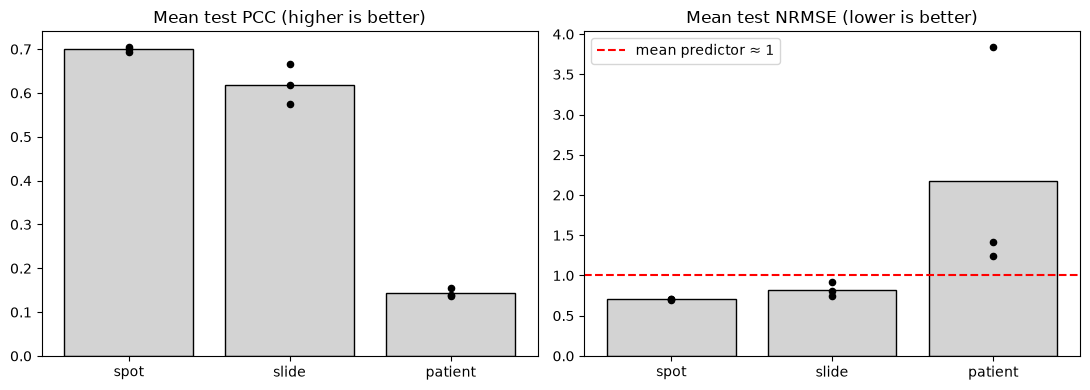

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x_positions = np.arange(len(SPLITS))

for ax, metric, title in [(axes[0], "ridge_PCC", "Mean test PCC (higher is better)"),
                          (axes[1], "ridge_NRMSE", "Mean test NRMSE (lower is better)")]:
    means = [fold_scores.loc[fold_scores["split"] == s, metric].mean() for s in SPLITS]
    ax.bar(x_positions, means, color="lightgray", edgecolor="black")
    for i, split in enumerate(SPLITS):
        fold_values = fold_scores.loc[fold_scores["split"] == split, metric]
        ax.scatter(np.full(len(fold_values), i), fold_values, color="black", zorder=3, s=20)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(SPLITS)
    ax.set_title(title)

axes[1].axhline(1.0, color="red", linestyle="--", label="mean predictor ≈ 1")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "leakage_plot.png", dpi=150)
plt.show()

**Best and worst genes under the patient split** (PCC averaged over folds, for genes chosen in at least one fold).

In [13]:
if "patient" in SPLITS:
    patient_genes = gene_scores[gene_scores["split"] == "patient"]
    gene_summary = patient_genes.groupby("gene").agg(PCC=("PCC", "mean"), folds=("fold", "count"))
    gene_summary = gene_summary.sort_values("PCC", ascending=False)
    print("Top 10:")
    print(gene_summary.head(10).round(3).to_string())
    print()
    print("Bottom 10:")
    print(gene_summary.tail(10).round(3).to_string())

Top 10:
                   PCC  folds
gene                         
ENSG00000019582  0.437      2
ENSG00000130203  0.409      3
ENSG00000204287  0.369      3
ENSG00000115414  0.341      3
ENSG00000166710  0.337      2
ENSG00000182492  0.330      1
ENSG00000101439  0.316      2
ENSG00000117984  0.312      1
ENSG00000184292  0.307      1
ENSG00000164919  0.307      2

Bottom 10:
                   PCC  folds
gene                         
ENSG00000091831 -0.007      1
ENSG00000125730 -0.007      2
ENSG00000112559 -0.012      1
ENSG00000197747 -0.017      1
ENSG00000142937 -0.032      2
ENSG00000120885 -0.052      1
ENSG00000147604 -0.066      2
ENSG00000163191 -0.080      1
ENSG00000205002 -0.083      1
ENSG00000251562 -0.098      1


## Step 6. Save everything

In [14]:
fold_scores.to_csv(RESULTS_DIR / "fold_scores.csv", index=False)
gene_scores.to_csv(RESULTS_DIR / "gene_scores.csv", index=False)
leakage_table.to_csv(RESULTS_DIR / "leakage_table.csv", index=False)

settings = {
    "splits": SPLITS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "n_pcs": N_PCS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "n_spots": int(len(spots)),
    "n_sections": int(spots["sample_id"].nunique()),
    "n_patients": int(spots["patient"].nunique()),
    "patients": sorted(spots["patient"].unique().tolist()),
}
with Path(RESULTS_DIR / "settings.json").open("w") as f:
    json.dump(settings, f, indent=2)

print("Saved to", RESULTS_DIR)
print(sorted([item.name for item in RESULTS_DIR.iterdir()]))

Saved to C:\Users\Siyu_\Documents\JHU_Files\courses\697_BDD\Hist2ST\outputs
['fold_assignments.csv', 'fold_scores.csv', 'gene_scores.csv', 'leakage_plot.png', 'leakage_table.csv', 'settings.json']


## How to read the test-run numbers

With 3 patients and 3 folds, the patient split trains on only **2 patients** each time, so its score will be low and noisy. That's expected. The test run is for checking that the pipeline works end to end; the real leakage result comes from all 23 patients with `N_FOLDS = 4`.